# Homework 3

Author: Khanh Do

### Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import warnings   # Turns off the future warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

## Question 1

The goal of this challenge is to obtain the best cross-validated F1 score for the SMS spam classification data set.

### 1. Read in Data

In [2]:
spam = pd.read_csv("https://remiller1450.github.io/data/sms_spam.txt", sep="\t", header=None, names=["label", "message"])
spam.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
# Separate predictors and outcome
spam_X = spam["message"]
spam_y = spam["label"].map({"ham": 0, "spam": 1})  # for classification

### 2. Explore Data

In [4]:
print("Data shape:", spam.shape)
print("N/A rows:", spam_X.isna().sum())
print("Empty rows:", spam_X.str.strip().eq("").sum())
print("Duplicate rows:", spam.duplicated().sum())

Data shape: (5572, 2)
N/A rows: 0
Empty rows: 0
Duplicate rows: 403


In [5]:
print(spam_y.value_counts())

label
0    4825
1     747
Name: count, dtype: int64


**Comment:** The data is imbalanced. F1 score will be used later.

In [6]:
print(spam.sample(25, random_state=5).to_string(index=False))

label                                                                                                                                                                  message
 spam                         PRIVATE! Your 2004 Account Statement for 07742676969 shows 786 unredeemed Bonus Points. To claim call 08719180248 Identifier Code: 45239 Expires
  ham                                                                                            No go. No openings for that room 'til after thanksgiving without an upcharge.
 spam          GENT! We are trying to contact you. Last weekends draw shows that you won a £1000 prize GUARANTEED. Call 09064012160. Claim Code K52. Valid 12hrs only. 150ppm 
  ham                                                                                                               Can you plz tell me the ans. BSLVYL sent via fullonsms.com
  ham                                                                                            I know girls always safe and

**Comment:** The spam messages often contain long phone number, monetary amounts, promotional language, instructions to call/reply and a sense of urgency. There is a lot of use of the exclamation mark ('!'), account-related words, and words to encourage action like "Expire", "CLaim", "Call", "Contact", etc. Ham messages seems more conversational, with typos, `...`, grammar errors, either extensive or none capitalization. Some contains links and seems shorter than spam. Thus, we should check for message length, word count, digit count, and exclamation mark count as the next exploration step. We can also count the number of money sign ('$', '£') and question mark sign ('?'). Capitalization is interesting, we can explore the proportion of capitalization letters to the whole text. These considerations will go into feature engineering later.

In [7]:
explore = spam.assign(
    message_length=spam_X.str.len(),
    word_count=spam_X.str.split().str.len(),
    digit_count=spam_X.str.count(r"\d"),
    exclamation_count=spam_X.str.count("!"),
    question_count=spam_X.str.count(r"\?"),
    smiley_count=spam_X.str.count(r":-?\)"),
    help_count=spam_X.str.count(r"(?i)\bhelp\b"),
    ur_count=spam_X.str.count(r"(?i)\bur\b")
)

display(explore.groupby("label")[["message_length", "word_count", "digit_count", "exclamation_count", "question_count", "smiley_count", "help_count", "ur_count"]].agg(["mean", "median"]))

message_length        word_count        digit_count         \
                mean median       mean median        mean median   
label                                                              
ham        71.482487   52.0  14.310259   11.0    0.305285    0.0   
spam      138.670683  149.0  23.911647   25.0   15.812584   16.0   

      exclamation_count        question_count        smiley_count         \
                   mean median           mean median         mean median   
label                                                                      
ham            0.176580    0.0       0.284974    0.0      0.07399    0.0   
spam           0.729585    0.0       0.234270    0.0      0.00000    0.0   

      help_count         ur_count         
            mean median      mean median  
label                                     
ham     0.007461    0.0  0.051192    0.0  
spam    0.029451    0.0  0.192771    0.0

**Comment:** Spam messages have longer length and more words. Spam messages have substantially more digits, which is consistent with what we saw previously. Although both spam and ham messages have a median of 0 for exclamation mark count, spam has more exclamation marks on average. The question mark count is pretty similar between ham and spam message, with ham message even have more on average. However, I'll retain this to see if combined with other features is meaningful. The smiley count (':-)') seems to only appear in ham messages.

### 3. Feature Engineering

In [8]:
def feature_engineering(input_text):
    text = input_text.fillna("")
    length = text.str.len()

    return pd.DataFrame({
        "message_length": length,
        "word_count": text.str.split().str.len(),
        "digit_count": text.str.count(r"\d"),
        "exclamation_count": text.str.count("!"),
        "question_count": text.str.count(r"\?"),

        "uppercase_proportion": (
            text.str.count(r"[A-Z]") / length.clip(lower=1)
        ),

        "has_link": text.str.contains(
            r"(?i)(?:https?://|www\.|\b[a-z0-9]+(?:-[a-z0-9]+)*"
            r"(?:\.[a-z0-9]+(?:-[a-z0-9]+)*)*"
            r"\.(?:com|org|net|co\.uk|uk|info|biz|mobi)\b)"
        ).astype(int),

        "has_currency": text.str.contains(
            r"[$£€]"
        ).astype(int),

        "has_phone_number": text.str.contains(
            r"(?<!\w)\+?\d(?:[ -]?\d){9,11}(?!\w)"
        ).astype(int),

        "account_word_count": text.str.count(
            r"(?i)\b(?:account|password|bank|banking|"
            r"login|verify|verification)\b"
        ),

        "promotion_word_count": text.str.count(
            r"(?i)\b(?:free|win|wins|won|winner|winners|selected|"
            r"prize|prizes|bonus|offers?|guaranteed|earn|"
            r"congratulations|congrats)\b"
        ),

        "action_word_count": text.str.count(
            r"(?i)\b(?:call|reply|claim|contact|text)\b"
        ),

        "urgency_word_count": text.str.count(
            r"(?i)\b(?:urgent|expires?|expiry|"
            r"immediately|deadline)\b"
        ),

        "has_smiley_face": text.str.contains(
            r"[:;]-?\)"
        ).astype(int),

        "help_word_count": text.str.count(
            r"(?i)\bhelp\b"
        ),
        
        "you_typo_count": text.str.count(
            r"(?i)\b(?:yur|ur|yuo|yoru)\b"
        )
    }, index=text.index)

In [9]:
# Check if this works
spam_X_FE = feature_engineering(spam_X)
display(spam_X_FE.sample(5, random_state=5))

,message_length,word_count,digit_count,exclamation_count,question_count,uppercase_proportion,has_link,has_currency,has_phone_number,account_word_count,promotion_word_count,action_word_count,urgency_word_count,has_smiley_face,help_word_count,you_typo_count
2095,144,20,34,1,0,0.111111,0,0,1,1,1,2,1,0,0,0
5343,77,13,0,0,0,0.025974,0,0,0,0,0,0,0,0,0,0
564,159,27,22,1,0,0.132075,0,1,1,0,3,3,0,0,0,0
3849,58,11,0,0,0,0.120690,1,0,0,0,0,0,0,0,0,0
3317,77,16,0,0,0,0.025974,0,0,0,0,0,0,0,0,0,0


**Comment:** Manual features that we just engineered are a start but we omit most vocabulary. I will add [CountVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html). It learns a vocabulary and creates a feature for each token. We will also need to use [FeatureUnion](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.FeatureUnion.html) to apply both the manual and vectorized words transformations.

In [14]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_extraction.text import CountVectorizer
def make_combined_features():
    return FeatureUnion([
        ("manual", FunctionTransformer(feature_engineering)),
        ("words", CountVectorizer(
                    binary=True, # binary presence 0/1 (instead of occurence counts)
                    ngram_range=(1, 1) # uses individual words
                ))
    ])

### 4. Compare tree models

Let's compare random forest and XGBoost.

#### a. Random Forest

**Randomized search**

In [15]:
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("features", make_combined_features()),
    ("model", RandomForestClassifier(n_estimators=300, random_state=5, n_jobs=1))
])

rf_params = {
    "model__max_depth": [5, 10, 20, None],
    "model__max_features": ["sqrt", 0.05, 0.1, 0.5],
    "model__min_samples_leaf": [1, 2, 5, 10],
    "model__class_weight": [None, "balanced"]
}

rf_search = RandomizedSearchCV(
    rf_pipeline, 
    param_distributions=rf_params,
    n_iter=30, 
    scoring="f1", 
    cv=5, 
    n_jobs=-1, 
    random_state=5
).fit(spam_X, spam_y)

print("Random Forest:")
print(rf_search.best_score_)
print(rf_search.best_params_)

Random Forest:
0.9565885650817159
{'model__min_samples_leaf': 1, 'model__max_features': 0.1, 'model__max_depth': 20, 'model__class_weight': 'balanced'}


**Grid search**

In [16]:
# Smaller pool to do grid search
rf_params_refined = {
    "model__max_depth": [20, None],
    "model__max_features": ["sqrt", 0.05, 0.1],
    "model__min_samples_leaf": [1, 2],
    "model__class_weight": [None, "balanced"]
}

rf_refined = GridSearchCV(
    rf_pipeline,
    param_grid=rf_params_refined, 
    scoring="f1", 
    cv=5, 
    n_jobs=-1
).fit(spam_X, spam_y)

print("Random Forest (refined search):")
print(rf_refined.best_score_)
print(rf_refined.best_params_)


Random Forest (refined search):
0.9631350199800558
{'model__class_weight': 'balanced', 'model__max_depth': 20, 'model__max_features': 0.05, 'model__min_samples_leaf': 1}


#### b. XGBoost

**Randomized search**

In [17]:
xgb_pipeline = Pipeline([
    ("features", make_combined_features()),
    ("model", xgb.XGBClassifier(eval_metric="logloss", random_state=5, n_jobs=1))
])

xgb_params = {
    "model__n_estimators": [100, 300, 500, 1000],
    "model__learning_rate": [0.05, 0.03, 0.01, 0.1],
    "model__max_depth": [2, 4, 6, 8],
    "model__min_child_weight": [1, 5, 10, 20],
    "model__subsample": [0.5, 0.75, 1.0],
    "model__colsample_bytree": [0.1, 0.5, 0.75, 1.0]
}

xgb_search = RandomizedSearchCV(
    xgb_pipeline,
    param_distributions=xgb_params,
    n_iter=30,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    random_state=5
).fit(spam_X, spam_y)

print("XGBoost:")
print(xgb_search.best_score_)
print(xgb_search.best_params_)

XGBoost:
0.9647642689297212
{'model__subsample': 0.75, 'model__n_estimators': 500, 'model__min_child_weight': 1, 'model__max_depth': 6, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.1}


**Grid search**

In [18]:
# Smaller pool to do grid search
xgb_params_refined = {
    "model__n_estimators": [500, 1000, 1500],
    "model__learning_rate": [0.01, 0.03, 0.05],
    "model__max_depth": [5, 6],
    "model__min_child_weight": [1],
    "model__subsample": [0.75, 1.0],
    "model__colsample_bytree": [0.1, 0.5]
}

xgb_refined = GridSearchCV(
    xgb_pipeline,
    param_grid=xgb_params_refined,
    scoring="f1",
    cv=5,
    n_jobs=-1
).fit(spam_X, spam_y)

print("XGBoost (refined search):")
print(xgb_refined.best_score_)
print(xgb_refined.best_params_)

XGBoost (refined search):
0.965473239356853
{'model__colsample_bytree': 0.1, 'model__learning_rate': 0.05, 'model__max_depth': 5, 'model__min_child_weight': 1, 'model__n_estimators': 500, 'model__subsample': 1.0}


### 5. Compare selected configurations across fold assignments

The two models had similar default-fold performance (`best_score=0.948`). Following the homework’s suggestion to try different fold assignments, I will evaulate both best estimators using the same shuffled five-fold splits. 

In [19]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import f1_score, precision_score, recall_score

models = {"Random forest": rf_refined.best_estimator_,
          "XGBoost": xgb_refined.best_estimator_}

# Default folds plus three shuffled assignments (fav seed numbers)
fold_settings = {
    "Default": 5,
    "Seed 3": KFold(n_splits=5, shuffle=True, random_state=3),
    "Seed 55": KFold(n_splits=5, shuffle=True, random_state=55),
    "Seed 67": KFold(n_splits=5, shuffle=True, random_state=67)
}

results = []
default_predictions = {}

for fold_name, folds in fold_settings.items():
    for model_name, model in models.items():
        pred = cross_val_predict(model, spam_X, spam_y, cv=folds, n_jobs=-1)
        results.append({"Model": model_name, "Folds": fold_name,
                        "F1": f1_score(spam_y, pred),
                        "Precision": precision_score(spam_y, pred),
                        "Recall": recall_score(spam_y, pred)})
        if fold_name == "Default": default_predictions[model_name] = pred
        
comparison = pd.DataFrame(results)
display(comparison)
print("Selected candidate settings for the final block:")
for name, model in models.items(): print(name, model.named_steps["model"])


,Model,Folds,F1,Precision,Recall
0,Random forest,Default,0.963215,0.980583,0.946452
1,XGBoost,Default,0.965565,0.994326,0.938420
2,Random forest,Seed 3,0.960000,0.972527,0.947791
3,XGBoost,Seed 3,0.964997,0.990141,0.941098
4,Random forest,Seed 55,0.963265,0.979253,0.947791
5,XGBoost,Seed 55,0.964852,0.994318,0.937082
6,Random forest,Seed 67,0.960000,0.972527,0.947791
7,XGBoost,Seed 67,0.964138,0.994310,0.935743


Selected candidate settings for the final block:
Random forest RandomForestClassifier(class_weight='balanced', max_depth=20, max_features=0.05,
                       n_estimators=300, n_jobs=1, random_state=5)
XGBoost XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.1, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=1, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=500, n_jobs=1,
              num_parallel_tree=None, ...)


**Comment:** Both models performed similarly across the evaluated fold assignments. XGBoost achieved higher precision and the highest default-fold F1, whereas random forest consistently achieved higher recall. Random forest also had slightly higher average F1 and less variation across the evaluated fold assignments. I will choose random forest for the beforementioned reasons as the final classifier. Also since I'm happy with F1 crossing 0.95 threshold consistently, I will not redo feature engineering.

### 6. Standalone final evaluation of one fixed pipeline

Final 5-fold F1: 0.9632152588555858
Precision: 0.9805825242718447
Recall: 0.9464524765729585


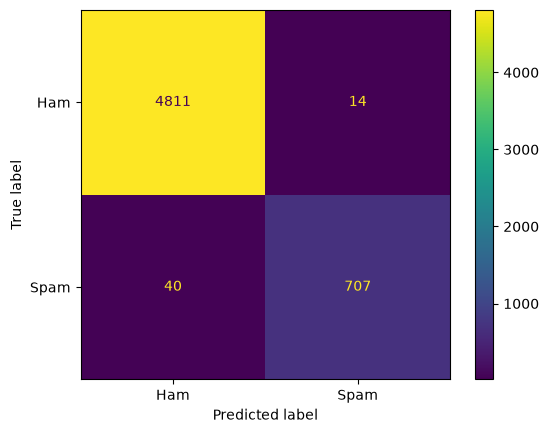

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, KFold, cross_val_predict
from sklearn.metrics import f1_score, precision_score, recall_score, ConfusionMatrixDisplay

def feature_engineering(input_text):
    text = input_text.fillna("")
    length = text.str.len()

    return pd.DataFrame({
        "message_length": length,
        "word_count": text.str.split().str.len(),
        "digit_count": text.str.count(r"\d"),
        "exclamation_count": text.str.count("!"),
        "question_count": text.str.count(r"\?"),

        "uppercase_proportion": (
            text.str.count(r"[A-Z]") / length.clip(lower=1)
        ),

        "has_link": text.str.contains(
            r"(?i)(?:https?://|www\.|\b[a-z0-9]+(?:-[a-z0-9]+)*"
            r"(?:\.[a-z0-9]+(?:-[a-z0-9]+)*)*"
            r"\.(?:com|org|net|co\.uk|uk|info|biz|mobi)\b)"
        ).astype(int),

        "has_currency": text.str.contains(
            r"[$£€]"
        ).astype(int),

        "has_phone_number": text.str.contains(
            r"(?<!\w)\+?\d(?:[ -]?\d){9,11}(?!\w)"
        ).astype(int),

        "account_word_count": text.str.count(
            r"(?i)\b(?:account|password|bank|banking|"
            r"login|verify|verification)\b"
        ),

        "promotion_word_count": text.str.count(
            r"(?i)\b(?:free|win|wins|won|winner|winners|selected|"
            r"prize|prizes|bonus|offers?|guaranteed|earn|"
            r"congratulations|congrats)\b"
        ),

        "action_word_count": text.str.count(
            r"(?i)\b(?:call|reply|claim|contact|text)\b"
        ),

        "urgency_word_count": text.str.count(
            r"(?i)\b(?:urgent|expires?|expiry|"
            r"immediately|deadline)\b"
        ),

        "has_smiley_face": text.str.contains(
            r"[:;]-?\)"
        ).astype(int),

        "help_word_count": text.str.count(
            r"(?i)\bhelp\b"
        ),
        
        "you_typo_count": text.str.count(
            r"(?i)\b(?:yur|ur|yuo|yoru)\b"
        )
    }, index=text.index)
    
def make_combined_features():
    return FeatureUnion([
        ("manual", FunctionTransformer(feature_engineering)),
        ("words", CountVectorizer(binary=True, ngram_range=(1, 1)))
    ])

# read in data 
spam = pd.read_csv("https://remiller1450.github.io/data/sms_spam.txt",
                   sep="\t", header=None, names=["label", "message"])
spam_X = spam["message"]
spam_y = spam["label"].map({"ham": 0, "spam": 1})

# chosen pipeline
final_pipeline = Pipeline([
    ("features", make_combined_features()),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=20, 
        max_features=0.05,
        min_samples_leaf=1, 
        class_weight="balanced", 
        random_state=5, 
        n_jobs=1
    ))
])

final_predictions = cross_val_predict(final_pipeline, spam_X, spam_y, cv=5, n_jobs=-1)

print("Final 5-fold F1:", f1_score(spam_y, final_predictions))
print("Precision:", precision_score(spam_y, final_predictions))
print("Recall:", recall_score(spam_y, final_predictions))
ConfusionMatrixDisplay.from_predictions(spam_y, final_predictions, display_labels=["Ham", "Spam"])
plt.show()

### 7. Modeling Philosophy and Choices

I represented each SMS message using manually engineered features and binary unigram indicators. Message inspection and class summaries motivated length, word and digit counts, punctuation, capitalization, currency, links, phone numbers, keyword groups, and smiley features. These manual feature engineering choices come from inspecting a random sample of spam/ham messages and assessing their average and median count. Because these summaries omit most vocabulary, I then used `CountVectorizer` to extract word-presence features and `FeatureUnion` to combine them with the manual features. I actually had some testing not included in this script that did not include `CountVectorize` and could not achieve an F1 score above 0.95. Then I did more research about `sklearn` and found this helpful tool. All transformations were placed inside pipelines so each training fold learned its own vocabulary. I compared random forest and XGBoost on this common representation, tuning hyperparameters with 5-fold spam F1 because spam is the minority class and both missed spam and false alarms matter. Random forest tuning included feature subsampling, depth, leaf size, and class weights; XGBoost tuning included learning rate, tree count, depth, child weight, and sampling. Scaling and PCA were not considered because they were not needed for the chosen tree pipelines. Randomized search was performed first to test across a bigger pool of candidate parameters combos, then a smaller grid-search was done - for each random forest and XGBoost pipeline. I checked selected configurations across several fold assignments and evaluated one fixed final pipeline using `cross_val_predict`. The disadvantage of my workflow is I do not know how it will perform on an unseen test set. Some manual feature I selected is specific to this dataset (e.g., only ham message has smiley face notation).

## Question 2

The goal of this challenge is to obtain the best ROC-AUC score on a time-series classification task.

### 1. Read in data

In [21]:
drug = pd.read_csv("https://remiller1450.github.io/data/drugdetection.csv")
drug.head()

,ID,Full_Sample_ID,DosingLevel,Target,CFS.Brake.Pedal.Force,CFS.Accelerator.Pedal.Position,CFS.Steering.Wheel.Angle,CFS.Steering.Wheel.Angle.Rate,SCC.Lane.Deviation.2,VDS.Veh.Speed
0,34,34_1_YM,YM,1,0.030653,0.383080,2.021470,3.345467,-5.376608,71.282471
1,34,34_1_YM,YM,1,-0.007314,0.385061,2.109360,3.961737,-5.422563,71.281548
2,34,34_1_YM,YM,1,-0.007314,0.386401,2.153305,3.961737,-5.469440,71.281052
3,34,34_1_YM,YM,1,0.002178,0.387513,2.197250,4.049776,-5.517264,71.280991
4,34,34_1_YM,YM,1,0.011669,0.388236,2.285140,3.521544,-5.564104,71.281364


**Comment:** `ID` and `Full_Sample_ID` should be removed.

### 2. Explore Data

In [ ]:
print("Data shape:", drug.shape)
print(drug.dtypes)
print("Missing values:")
print(drug.isna().sum())

# Check the outcome and participant within each driving sample
drug_groups = drug.groupby("Full_Sample_ID", sort=False)
drug_sample_sizes = drug_groups.size()
print("Number of samples:", len(drug_sample_sizes))
print("Number of participants:", drug["ID"].nunique())
print("Time steps per sample:")
print(drug_sample_sizes.value_counts())

assert drug["Full_Sample_ID"].notna().all()
assert drug_sample_sizes.eq(3600).all()  # 3600 time steps per sample
assert drug_groups["Target"].nunique().eq(1).all()
assert drug_groups["ID"].nunique().eq(1).all()
assert drug_groups["DosingLevel"].nunique().eq(1).all()
assert drug["Target"].isin([0, 1]).all()
assert drug["Target"].eq(drug["DosingLevel"].isin(["YM", "ZM"]).astype(int)).all()

# Count classes at the sample level
drug_sample_info = drug_groups[["ID", "DosingLevel", "Target"]].first()
print(drug_sample_info["Target"].value_counts())
print(drug_sample_info["Target"].value_counts(normalize=True) * 100)

Data shape: (608400, 10)
ID                                  int64
Full_Sample_ID                        str
DosingLevel                           str
Target                              int64
CFS.Brake.Pedal.Force             float64
CFS.Accelerator.Pedal.Position    float64
CFS.Steering.Wheel.Angle          float64
CFS.Steering.Wheel.Angle.Rate     float64
SCC.Lane.Deviation.2              float64
VDS.Veh.Speed                     float64
dtype: object
Missing values:
ID                                0
Full_Sample_ID                    0
DosingLevel                       0
Target                            0
CFS.Brake.Pedal.Force             0
CFS.Accelerator.Pedal.Position    0
CFS.Steering.Wheel.Angle          0
CFS.Steering.Wheel.Angle.Rate     0
SCC.Lane.Deviation.2              0
VDS.Veh.Speed                     0
dtype: int64
Number of samples: 169
Number of participants: 19
Time steps per sample:
3600    169
Name: count, dtype: int64
Target
1    111
0     58
Name: count, dty

Target,0,1
ID,,
3,3,6
7,3,6
10,3,6
15,3,6
17,3,3
18,3,6
21,3,6
25,3,6
26,3,6


**Comment:** 